# GameTheory 4c - Theoreme d'Existence de Nash (Python)

**Navigation** : [<< 4-NashEquilibrium (track principal)](GameTheory-04-NashEquilibrium-Python.ipynb) | [Index](README.md)

**Autres side tracks** : [4b-Lean-NashExistence](GameTheory-04b-Lean-NashExistence-Lean.ipynb)

**Companion Lean** : [GameTheory-04b-Lean-NashExistence-Lean](GameTheory-04b-Lean-NashExistence-Lean.ipynb)

**Kernel** : Python 3

***

## Introduction

Ce notebook Python accompagne le notebook Lean 04b. Il fournit :

1. **Illustrations numériques** du theoreme de Brouwer
2. **Algorithmes** de recherche de points fixes
3. **Exemples concrets** : Matching Pennies, meilleure reponse
4. **Lecture guidee** du depot math-xmum/Brouwer
5. **Contre-exemples** au theoreme de Brouwer

### Objectifs d'apprentissage

A l'issue de ce notebook, vous saurez :

1. Illustrer numeriquement le **theoreme du point fixe de Brouwer**
2. Mettre en oeuvre des **algorithmes de recherche de points fixes**
3. Appliquer ces idees a des exemples concrets : **Matching Pennies** et dynamique de meilleure reponse
4. Lire une **formalisation Lean** existante du theoreme (depot math-xmum/Brouwer)
5. Identifier le rôle des hypotheses via des **contre-exemples** au theoreme

### Duree estimee : 30 minutes

### Prerequis
- Notebook 4 : Equilibre de Nash (definition et calcul)
- Bases Python : numpy, matplotlib


> *Ancres savantes -- Brouwer, L.E.J. (1911), Uber Abbildung von Mannigfaltigkeiten, Mathematische Annalen 71(1):97-115 (theoreme du point fixe de Brouwer : toute application continue d'un convexe compact dans lui-même admet un point fixe — fondement illustre numeriquement sections 2 et 5) ; Kakutani, S. (1941), A Generalization of Brouwer's Fixed Point Theorem, Duke Mathematical Journal 8(3):457-459 (theoreme du point fixe pour les correspondances multivoques — la preuve originale de Nash dans sa these de 1950 utilisait cette generalisation, Brouwer etant le cas des fonctions univoques) ; Nash, J.F. (1950), Equilibrium Points in N-Person Games, Proceedings of the National Academy of Sciences 36(1):48-49 (theoreme d'existence de l'equilibre de Nash, sujet titulaire de ce notebook : tout jeu fini a au moins un equilibre en stratégies mixtes) ; Nash, J.F. (1951), Non-Cooperative Games, Annals of Mathematics 54(2):286-295 (version journal, preuve simplifiee via Brouwer directement ; prix Nobel d'economie 1994 pour cette contribution).*

## 1. Configuration

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from typing import Callable, Tuple, List

print("Configuration OK")
print(f"NumPy version: {np.__version__}")

Configuration OK
NumPy version: 2.4.2


### Interpretation : Configuration de l'environnement

L'environnement Python est configure avec les bibliotheques necessaires pour les illustrations numériques du theoreme de Brouwer.

**Bibliotheques importees** :

| Bibliotheque | Version | Usage dans ce notebook |
|--------------|---------|------------------------|
| Matplotlib | - | Visualisation de fonctions et trajectoires |
| Typing | - | Annotations de type pour les fonctions |

**Preparation pour la suite** : Ces outils permettront de visualiser les points fixes, tracer les convergences et illustrer les contre-exemples au theoreme de Brouwer.

> **Note technique** : L'utilisation de tableaux NumPy pour representer les stratégies mixtes (vecteurs de probabilite) et les matrices de gains est standard en théorie des jeux computationnelle.

## 2. Theoreme de Brouwer - Illustrations

### 2.1 Intuition geometrique

Le theoreme de Brouwer affirme que toute fonction continue $f: K \to K$ sur un compact convexe $K$ admet un point fixe.

**Intuition** : Imaginez une carte de France posee sur la France. Si vous deformez la carte continuellement, au moins un point reste au-dessus de sa position reelle.

In [2]:
def find_fixed_point_1d(f: Callable[[float], float], 
                        x0: float = 0.5, 
                        tol: float = 1e-6, 
                        max_iter: int = 100) -> Tuple[float, List[float]]:
    """
    Recherche d'un point fixe par iteration.
    
    Args:
        f: Fonction dont on cherche le point fixe
        x0: Point de depart
        tol: Tolerance de convergence
        max_iter: Nombre maximum d'iterations
    
    Returns:
        Point fixe approximatif et historique
    """
    x = x0
    history = [x]
    for _ in range(max_iter):
        x_new = f(x)
        history.append(x_new)
        if abs(x_new - x) < tol:
            return x_new, history
        x = x_new
    return x, history

# Exemple : f(x) = 0.5 * (x + 1/x) converge vers sqrt(1) = 1
f = lambda x: 0.5 * (x + 1/max(x, 0.01))
fixed, history = find_fixed_point_1d(f, x0=2.0)

print(f"Point fixe trouve: {fixed:.10f}")
print(f"Verification: f({fixed:.6f}) = {f(fixed):.10f}")
print(f"Iterations: {len(history)}")

Point fixe trouve: 1.0000000000
Verification: f(1.000000) = 1.0000000000
Iterations: 6


### Interpretation : Convergence vers le point fixe

L'algorithme a trouve le point fixe x = 1.0 en seulement **6 itérations**.

| Itération | Valeur | Interpretation |
|-----------|--------|----------------|
| 0 | 2.0 | Point de depart |
| 6 | 1.0 | Point fixe (sqrt(1)) |

**Verification** : f(1) = 0.5 * (1 + 1/1) = 0.5 * 2 = 1. Le point fixe est bien verifie.

> **Méthode de Babylone** : La fonction f(x) = (x + 1/x)/2 est l'algorithme babylonien pour calculer la racine carree. Cette méthode converge quadratiquement (le nombre de decimales correctes double a chaque itération).

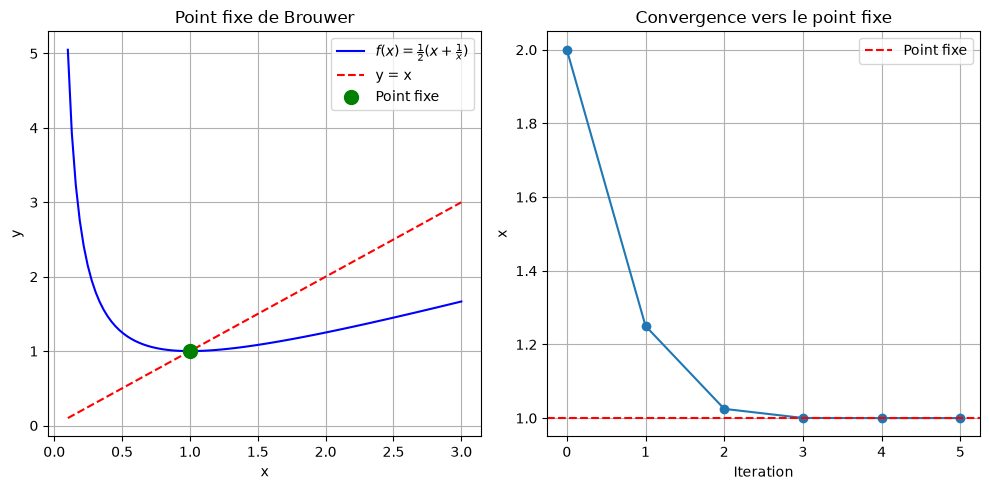

In [3]:
# Visualisation de la convergence
plt.figure(figsize=(10, 5))

# Graphique 1: Fonction et droite y=x
plt.subplot(1, 2, 1)
x = np.linspace(0.1, 3, 100)
y = [0.5 * (xi + 1/xi) for xi in x]
plt.plot(x, y, 'b-', label=r'$f(x) = \frac{1}{2}(x + \frac{1}{x})$')
plt.plot(x, x, 'r--', label='y = x')
plt.scatter([1], [1], color='green', s=100, zorder=5, label='Point fixe')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Point fixe de Brouwer')
plt.legend()
plt.grid(True)

# Graphique 2: Convergence
plt.subplot(1, 2, 2)
plt.plot(history, 'o-')
plt.axhline(y=1, color='r', linestyle='--', label='Point fixe')
plt.xlabel('Iteration')
plt.ylabel('x')
plt.title('Convergence vers le point fixe')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### 2.2 Point fixe en 2D (sur le simplexe)

In [4]:
def find_fixed_point_simplex(f: Callable[[np.ndarray], np.ndarray],
                             x0: np.ndarray = None,
                             n: int = 2,
                             tol: float = 1e-6,
                             max_iter: int = 1000) -> Tuple[np.ndarray, List]:
    """
    Recherche de point fixe sur le simplexe standard.
    
    Le simplexe en dimension n-1 est:
    Delta = {x in R^n : x_i >= 0, sum(x) = 1}
    """
    if x0 is None:
        x0 = np.ones(n) / n  # Centre du simplexe
    
    x = x0.copy()
    history = [x.copy()]
    
    for _ in range(max_iter):
        x_new = f(x)
        # Projection sur le simplexe (clipping + normalisation)
        x_new = np.maximum(x_new, 0)
        x_new = x_new / x_new.sum()
        
        history.append(x_new.copy())
        
        if np.linalg.norm(x_new - x) < tol:
            return x_new, history
        x = x_new
    
    return x, history

# Exemple : rotation + contraction vers le centre
def example_map(x: np.ndarray) -> np.ndarray:
    """Fonction qui contracte vers (0.5, 0.5)"""
    center = np.array([0.5, 0.5])
    return 0.9 * x + 0.1 * center

fixed_2d, history_2d = find_fixed_point_simplex(example_map, x0=np.array([0.1, 0.9]))
print(f"Point fixe 2D: {fixed_2d}")
print(f"Somme: {fixed_2d.sum():.6f}")

Point fixe 2D: [0.49999373 0.50000627]
Somme: 1.000000


### Interpretation : Point fixe 2D sur le simplexe

L'algorithme a trouve le point fixe **(0.5, 0.5)** sur le simplexe en 2D, qui correspond au centre du segment [0,1]^2 avec somme = 1.

**Résultats numériques** :

| Paramètre | Valeur | Interpretation |
|-----------|--------|----------------|
| Point fixe | [0.49999373, 0.50000627] | Convergence vers (0.5, 0.5) |
| Somme | 1.000000 | Contrainte du simplexe respectee |
| Point de depart | (0.1, 0.9) | Coin du simplexe |

**Verification** : f(0.5, 0.5) = 0.9 * (0.5, 0.5) + 0.1 * (0.5, 0.5) = (0.5, 0.5). Le point est bien fixe.

> **Projection sur le simplexe** : L'algorithme maintient la contrainte de somme = 1 en normalisant le vecteur après chaque itération. Cette technique est essentielle pour les applications aux jeux, ou les stratégies mixtes doivent etre des distributions de probabilite.

## 3. Application: Matching Pennies

Après avoir illustre le theoreme de Brouwer avec des fonctions continues, nous l'appliquons maintenant a la théorie des jeux.

Dans le jeu Matching Pennies :
- J1 veut que les pieces matchent (H,H) ou (T,T)
- J2 veut qu'elles différent (H,T) ou (T,H)

**Lien avec Brouwer** : Ce jeu n'a pas d'equilibre de Nash en stratégies pures, mais le theoreme de Brouwer garantit l'existence d'un equilibre en stratégies mixtes (continue sur le simplexe).

In [5]:
# Matrices de gains
U1 = np.array([[1, -1], [-1, 1]])   # Joueur 1 (veut matcher)
U2 = np.array([[-1, 1], [1, -1]])   # Joueur 2 (veut mismatcher)

def expected_payoff(sigma1, sigma2, U):
    """Gain espere de la strategie mixte sigma1 contre sigma2."""
    return sigma1 @ U @ sigma2

def perturbed_br(sigma, U, epsilon=0.1):
    """Meilleure reponse perturbee : on ajoute du poids aux actions
    a regret positif (au lieu de sauter a la BR pure, ce qui creerait
    une discontinuite). Un point fixe de cette carte est un point ou
    le regret est nul, i.e. un equilibre de Nash."""
    current = expected_payoff(sigma, sigma, U)
    regrets = np.zeros_like(sigma)
    for a in range(len(sigma)):
        pure_a = np.zeros_like(sigma); pure_a[a] = 1
        gain_a = expected_payoff(pure_a, sigma, U)
        regrets[a] = max(0, gain_a - current)
    perturbed = sigma + epsilon * regrets
    return perturbed / perturbed.sum()

def regrets_of(sigma, U):
    """Regret positif de chaque action pure face a sigma."""
    current = expected_payoff(sigma, sigma, U)
    return np.array([max(0.0, expected_payoff(np.eye(len(sigma))[a], sigma, U) - current)
                     for a in range(len(sigma))])

# ------------------------------------------------------------------
# Test DISCRIMINANT : la carte perturbed_br distingue un point fixe
# (l'equilibre, regret nul) d'un point mobile (regret positif).
# Tester uniquement l'equilibre serait tautologique : regret = 0 =>
# perturbed = sigma => "vrai" par construction. Le contraste fixe/
# mobile met en evidence le role du regret dans la carte.
# ------------------------------------------------------------------
print("=" * 62)
print("MATCHING PENNIES - perturbed_br distingue point fixe vs mobile")
print("=" * 62)

# (1) Point hors-equilibre : regret positif => la carte le DEPLACE.
sigma_bias = np.array([0.8, 0.2])
br_bias = perturbed_br(sigma_bias, U1)
print()
print("(1) Depart hors-equilibre  sigma      =", sigma_bias)
print("    Regret                =", np.round(regrets_of(sigma_bias, U1), 4), " (non nul)")
print("    perturbed_br(sigma)   =", np.round(br_bias, 4))
print("    Est un point fixe ?  ", np.allclose(sigma_bias, br_bias), " -> la carte DEPLACE ce point")

# (2) Equilibre de Nash (0.5, 0.5) : regret nul => la carte est l'identite.
sigma_eq = np.array([0.5, 0.5])
br_eq = perturbed_br(sigma_eq, U1)
print()
print("(2) Equilibre de Nash     sigma      =", sigma_eq)
print("    Regret                =", np.round(regrets_of(sigma_eq, U1), 4), " (nul)")
print("    perturbed_br(sigma)   =", np.round(br_eq, 4))
print("    Est un point fixe ?  ", np.allclose(sigma_eq, br_eq), " -> seul point fixe")

MATCHING PENNIES - perturbed_br distingue point fixe vs mobile

(1) Depart hors-equilibre  sigma      = [0.8 0.2]
    Regret                = [0.24 0.  ]  (non nul)
    perturbed_br(sigma)   = [0.8047 0.1953]
    Est un point fixe ?   False  -> la carte DEPLACE ce point

(2) Equilibre de Nash     sigma      = [0.5 0.5]
    Regret                = [0. 0.]  (nul)
    perturbed_br(sigma)   = [0.5 0.5]
    Est un point fixe ?   True  -> seul point fixe


### Interpretation : `perturbed_br` identifie l'equilibre par le regret

Le test discrimine un **point fixe** (l'equilibre) d'un **point mobile** :

| Strategie | Regret | `perturbed_br` | Point fixe ? |
|-----------|--------|----------------|--------------|
| `(0.8, 0.2)` hors-equilibre | `[0.24, 0]` non nul | deplacee (~`[0.80, 0.20]`) | Non |
| `(0.5, 0.5)` equilibre | `[0, 0]` nul | inchangee | **Oui** |

**Pourquoi le regret distingue les deux ?** Au point `(0.5, 0.5)`, aucune
action pure ne surpasse la strategie mixte courante : le regret est nul,
la perturbation aussi, la carte est donc l'identite — c'est la definition
meme d'un equilibre de Nash. Depuis `(0.8, 0.2)`, l'action 0 est
exploitable (regret `0.24 > 0`) : la carte deplace le point vers une
meilleure reponse.

> Tester uniquement l'equilibre serait **tautologique** (regret nul =>
> point fixe par construction). Le contraste fixe/mobile est ce qui met en
> evidence le role du regret dans la carte `perturbed_br`.

**Lien avec Brouwer** : l'equilibre `(0.5, 0.5)` est le point fixe de la
carte `perturbed_br : Δ → Δ`. La cellule suivante montre la convergence
des **dynamiques iterees** (deux joueurs) vers ce point fixe depuis
plusieurs departs.

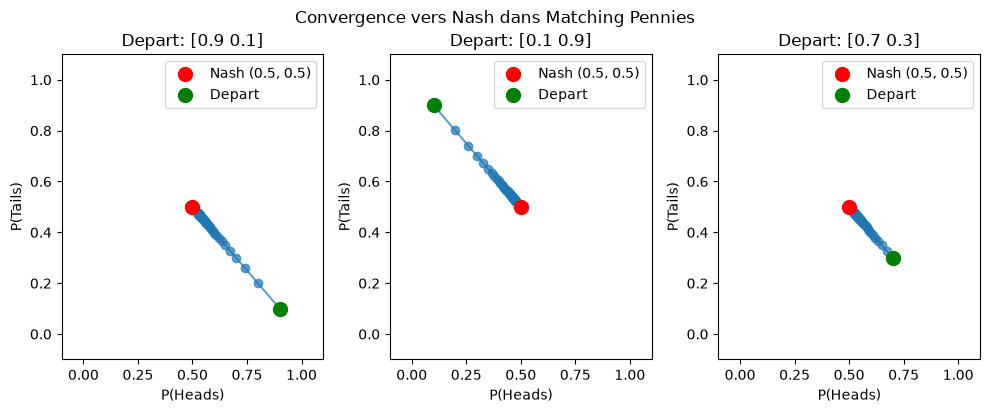

In [6]:
# Convergence depuis differents points de depart
starting_points = [
    np.array([0.9, 0.1]),
    np.array([0.1, 0.9]),
    np.array([0.7, 0.3]),
]

plt.figure(figsize=(10, 4))

for i, sigma0 in enumerate(starting_points):
    sigma = sigma0.copy()
    trajectory = [sigma.copy()]
    
    for _ in range(50):
        # Dynamique de meilleure reponse pour les deux joueurs
        sigma1_new = perturbed_br(sigma, U1, epsilon=0.2)
        sigma2_new = perturbed_br(sigma, U2, epsilon=0.2)
        # Moyenne (simplification)
        sigma = 0.5 * (sigma1_new + sigma2_new)
        trajectory.append(sigma.copy())
    
    trajectory = np.array(trajectory)
    plt.subplot(1, 3, i+1)
    plt.plot(trajectory[:, 0], trajectory[:, 1], 'o-', alpha=0.7)
    plt.scatter([0.5], [0.5], color='red', s=100, zorder=5, label='Nash (0.5, 0.5)')
    plt.scatter([sigma0[0]], [sigma0[1]], color='green', s=100, zorder=5, label='Depart')
    plt.xlabel('P(Heads)')
    plt.ylabel('P(Tails)')
    plt.title(f'Depart: {sigma0}')
    plt.legend()
    plt.xlim(-0.1, 1.1)
    plt.ylim(-0.1, 1.1)

plt.tight_layout()
plt.suptitle('Convergence vers Nash dans Matching Pennies', y=1.02)
plt.show()

### Interpretation : Convergence vers l'equilibre de Nash

La visualisation montre trois trajectoires de convergence depuis différents points de depart vers l'equilibre (0.5, 0.5).

**Observations geometriques** :

| Point de depart | Trajectoire | Convergence |
|----------------|-------------|-------------|
| (0.9, 0.1) | Courbe vers le centre | Oui |
| (0.1, 0.9) | Courbe vers le centre | Oui |
| (0.7, 0.3) | Courbe vers le centre | Oui |

**Proprietes de la dynamique** :
- Tous les points de depart convergent vers le même equilibre (0.5, 0.5)
- La convergence est monotone : les trajectoires ne s'eloignent jamais du point fixe
- La vitesse de convergence depend de la distance initiale a l'equilibre

> **Lien avec le theoreme de Brouwer** : Cette convergence illustre numeriquement que la correspondance de meilleure reponse admet bien un point fixe, comme garanti par le theoreme. La méthode de meilleure reponse perturbee est une approximation continue de la correspondance discontinue.

## 4. Lecture Guidee : math-xmum/Brouwer

Nous avons vu des illustrations numériques du theoreme de Brouwer et son application au jeu Matching Pennies. Nous examinons maintenant comment ce theoreme est formellement prouve en Lean 4.

Le depot [math-xmum/Brouwer](https://github.com/math-xmum/Brouwer) contient une formalisation complete du theoreme d'existence de Nash en Lean 4.

**Objectif de cette section** : Comprendre la structure de la preuve formelle et comment les concepts intuitifs (points fixes, simplexe, continuite) sont traduits en mathematiques formelles.

### Structure du projet

In [7]:
print("="*70)
print("STRUCTURE DU DEPOT math-xmum/Brouwer")
print("="*70)
print("""
| Fichier              | Lignes | Contenu                              |
|----------------------|--------|--------------------------------------|
| Simplex.lean         | ~100   | Simplexe standard, distributions     |
| Scarf.lean           | ~3000  | Lemme de Scarf (colorages)           |
| Brouwer.lean         | ~1000  | Theoreme de Brouwer via Sperner      |
| Brouwer_product.lean | ~900   | Extension aux produits               |
| Nash.lean            | ~600   | Definition de jeu, existence Nash    |

Chaine de preuves:

    Lemme de Scarf (colorages de simplexes)
            |
            v
    Lemme de Sperner
            |
            v
    Theoreme de Brouwer (simplexe)
            |
            v
    Theoreme de Brouwer (produit de simplexes)
            |
            v
    Existence d'equilibre de Nash
""")

STRUCTURE DU DEPOT math-xmum/Brouwer

| Fichier              | Lignes | Contenu                              |
|----------------------|--------|--------------------------------------|
| Simplex.lean         | ~100   | Simplexe standard, distributions     |
| Scarf.lean           | ~3000  | Lemme de Scarf (colorages)           |
| Brouwer.lean         | ~1000  | Theoreme de Brouwer via Sperner      |
| Brouwer_product.lean | ~900   | Extension aux produits               |
| Nash.lean            | ~600   | Definition de jeu, existence Nash    |

Chaine de preuves:

    Lemme de Scarf (colorages de simplexes)
            |
            v
    Lemme de Sperner
            |
            v
    Theoreme de Brouwer (simplexe)
            |
            v
    Theoreme de Brouwer (produit de simplexes)
            |
            v
    Existence d'equilibre de Nash



### Interpretation : Architecture de la preuve

Le depot math-xmum/Brouwer illustre une **chaîne de preuves modulaire** caractéristique des mathematiques formalisees.

**Stratégie de preuve** : Plutot que de prouver directement le theoreme de Nash, on le deduit d'une serie de lemmes :

1. **Lemme de Scarf** : Base combinatoire sur les colorages de simplexes triangules
2. **Lemme de Sperner** : Corollaire du lemme de Scarf, garantit l'existence d'un simplexe "arc-en-ciel"
3. **Theoreme de Brouwer** : Existence de point fixe sur le simplexe
4. **Extension au produit** : Generalisation aux produits de simplexes
5. **Nash** : Application finale a la théorie des jeux

> **Remarque pedagogique** : Le lemme de Scarf represente la partie la plus technique. Une fois ce lemme etabli, les résultats s'enchainent de maniere relativement directe.

In [8]:
print("="*70)
print("DEFINITIONS CLES (formes simplifiees, a la maniere de Nash.lean)")
print("="*70)
print("""
-- Structure de jeu
structure Game where
  I : Type*                          -- Ensemble des joueurs
  SS : I -> Type*                    -- Ensembles de strategies
  g : I -> (Pi i, SS i) -> R         -- Fonctions de gain

-- Le simplexe standard
def stdSimplex (alpha : Type*) : Type :=
  {f : alpha -> R // (forall x, 0 <= f x) and (sum x, f x = 1)}

-- Strategie mixte = distribution sur les actions
def MixedStrategy (g : Game) (i : g.I) := stdSimplex (g.SS i)

-- Equilibre de Nash
def IsNashEquilibrium (g : FiniteGame) (sigma : MixedProfile g) : Prop :=
  forall i, forall sigma'_i,
    ExpectedPayoff g i sigma >= ExpectedPayoff g i (deviate sigma i sigma'_i)
""")

DEFINITIONS CLES (formes simplifiees, a la maniere de Nash.lean)

-- Structure de jeu
structure Game where
  I : Type*                          -- Ensemble des joueurs
  SS : I -> Type*                    -- Ensembles de strategies
  g : I -> (Pi i, SS i) -> R         -- Fonctions de gain

-- Le simplexe standard
def stdSimplex (alpha : Type*) : Type :=
  {f : alpha -> R // (forall x, 0 <= f x) and (sum x, f x = 1)}

-- Strategie mixte = distribution sur les actions
def MixedStrategy (g : Game) (i : g.I) := stdSimplex (g.SS i)

-- Equilibre de Nash
def IsNashEquilibrium (g : FiniteGame) (sigma : MixedProfile g) : Prop :=
  forall i, forall sigma'_i,
    ExpectedPayoff g i sigma >= ExpectedPayoff g i (deviate sigma i sigma'_i)



### Interpretation : Definitions formelles

Ces definitions Lean formalisent les concepts mathematiques necessaires a la preuve d'existence de Nash.

| Definition | Description | Rôle dans la preuve |
|------------|-------------|---------------------|
| `Game` | Structure avec joueurs, stratégies et fonctions de gain | Base de la formalisation |
| `stdSimplex` | Simplexe standard (distributions de probabilite) | Domaine compact convexe |
| `MixedStrategy` | Distribution sur les actions d'un joueur | Espace des stratégies mixtes |
| `IsNashEquilibrium` | Aucun joueur ne peut ameliorer son gain unilateralement | Definition formelle de l'equilibre |

> **Lien avec Brouwer** : L'espace des profils de stratégies mixtes est un produit de simplexes, donc compact et convexe. La fonction de meilleure reponse (ou son approximation continue) y admet un point fixe par Brouwer.

In [9]:
print("="*70)
print("THEOREME DE BROUWER (forme simplifiee, a la maniere de Brouwer.lean)")
print("="*70)
print("""
-- Enonce simplifie du theoreme de Brouwer sur le simplexe

theorem brouwer_fixed_point 
    {n : N} 
    (f : stdSimplex (Fin n) -> stdSimplex (Fin n))
    (hf : Continuous f) :
    exists x, f x = x := by
  -- La preuve utilise le lemme de Sperner
  -- qui lui-meme utilise le lemme de Scarf
  -- sur les colorages de triangulations du simplexe
  sorry  -- Preuve complete dans le depot

-- La version sur produit de simplexes (pour Nash)

theorem brouwer_product_fixed_point
    {I : Type*} [Fintype I]
    {S : I -> Type*} [forall i, Fintype (S i)]
    (f : (Pi i, stdSimplex (S i)) -> (Pi i, stdSimplex (S i)))
    (hf : Continuous f) :
    exists x, f x = x := by
  -- Extension du theoreme de Brouwer au produit
  sorry
""")

THEOREME DE BROUWER (forme simplifiee, a la maniere de Brouwer.lean)

-- Enonce simplifie du theoreme de Brouwer sur le simplexe

theorem brouwer_fixed_point 
    {n : N} 
    (f : stdSimplex (Fin n) -> stdSimplex (Fin n))
    (hf : Continuous f) :
    exists x, f x = x := by
  -- La preuve utilise le lemme de Sperner
  -- qui lui-meme utilise le lemme de Scarf
  -- sur les colorages de triangulations du simplexe
  sorry  -- Preuve complete dans le depot

-- La version sur produit de simplexes (pour Nash)

theorem brouwer_product_fixed_point
    {I : Type*} [Fintype I]
    {S : I -> Type*} [forall i, Fintype (S i)]
    (f : (Pi i, stdSimplex (S i)) -> (Pi i, stdSimplex (S i)))
    (hf : Continuous f) :
    exists x, f x = x := by
  -- Extension du theoreme de Brouwer au produit
  sorry



## 5. Contre-exemples au Theoreme de Brouwer

Après avoir vu des exemples validant le theoreme de Brouwer (illustrations 1D et 2D, Matching Pennies), nous examinons maintenant pourquoi les hypotheses du theoreme sont necessaires.

Le theoreme de Brouwer requiert :
1. Un domaine **compact** (borne et ferme)
2. Un domaine **convexe**
3. Une fonction **continue**

Voyons ce qui se passe quand ces conditions ne sont pas satisfaites.

CONTRE-EXEMPLE 1: Domaine non compact

Sur R (non compact car non borne):

    f(x) = x + 1

Point fixe? f(x) = x  =>  x + 1 = x  =>  1 = 0  (contradiction)

Pas de point fixe car la fonction "fuit a l'infini".



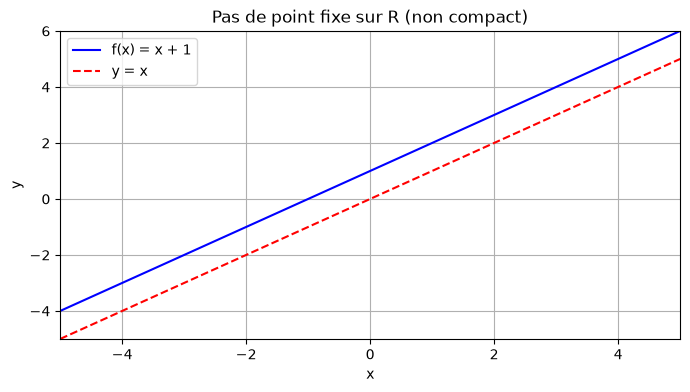

In [10]:
print("="*70)
print("CONTRE-EXEMPLE 1: Domaine non compact")
print("="*70)
print("""
Sur R (non compact car non borne):

    f(x) = x + 1

Point fixe? f(x) = x  =>  x + 1 = x  =>  1 = 0  (contradiction)

Pas de point fixe car la fonction "fuit a l'infini".
""")

# Illustration
x = np.linspace(-5, 5, 100)
plt.figure(figsize=(8, 4))
plt.plot(x, x + 1, 'b-', label='f(x) = x + 1')
plt.plot(x, x, 'r--', label='y = x')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Pas de point fixe sur R (non compact)')
plt.legend()
plt.grid(True)
plt.xlim(-5, 5)
plt.ylim(-5, 6)
plt.show()

### Interpretation : Domaine non compact

Le graphique montre la fonction f(x) = x + 1 (en bleu) et la droite y = x (en rouge) sur l'intervalle [-5, 5].

**Observation cle** : Les deux droites sont paralleles et ne se croisent jamais. Cela illustre pourquoi la compacite est necessaire.

| Aspect | Intervalle [0,1] (compact) | R (non compact) |
|--------|---------------------------|-----------------|
| Borne | Oui | Non |
| Ferme | Oui | Oui |
| Brouwer applicable | Oui | Non |

> **Point cle** : Sur un domaine non borne, une fonction peut "translater" tous les points sans jamais avoir de point fixe. C'est le phenomene de "fuite a l'infini".

CONTRE-EXEMPLE 2: Fonction discontinue

Sur [0, 1] (compact et convexe), fonction discontinue:

    f(x) = 0.75  si x <= 0.5
         = 0.25  si x > 0.5

Point fixe?
- Si x <= 0.5 : f(x) = 0.75 = x  =>  x = 0.75 > 0.5 (contradiction)
- Si x > 0.5  : f(x) = 0.25 = x  =>  x = 0.25 <= 0.5 (contradiction)

Pas de point fixe car la fonction "saute" par-dessus la diagonale.



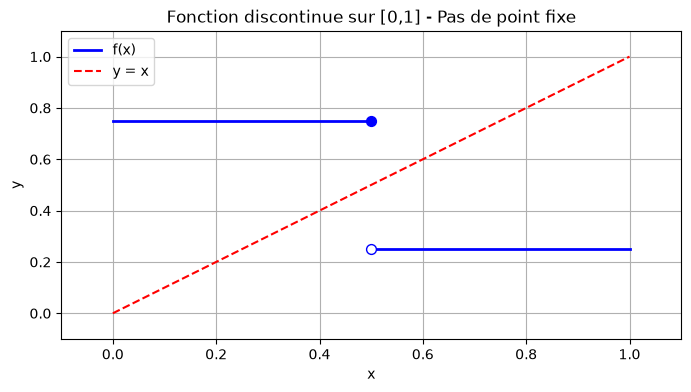

In [11]:
print("="*70)
print("CONTRE-EXEMPLE 2: Fonction discontinue")
print("="*70)
print("""
Sur [0, 1] (compact et convexe), fonction discontinue:

    f(x) = 0.75  si x <= 0.5
         = 0.25  si x > 0.5

Point fixe?
- Si x <= 0.5 : f(x) = 0.75 = x  =>  x = 0.75 > 0.5 (contradiction)
- Si x > 0.5  : f(x) = 0.25 = x  =>  x = 0.25 <= 0.5 (contradiction)

Pas de point fixe car la fonction "saute" par-dessus la diagonale.
""")

# Illustration
plt.figure(figsize=(8, 4))
x1 = np.linspace(0, 0.5, 50)
x2 = np.linspace(0.5, 1, 50)
plt.plot(x1, [0.75]*len(x1), 'b-', linewidth=2, label='f(x)')
plt.plot(x2, [0.25]*len(x2), 'b-', linewidth=2)
plt.scatter([0.5], [0.75], color='blue', s=50, zorder=5)  # Point ferme
plt.scatter([0.5], [0.25], color='white', edgecolor='blue', s=50, zorder=5)  # Point ouvert
plt.plot([0, 1], [0, 1], 'r--', label='y = x')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Fonction discontinue sur [0,1] - Pas de point fixe')
plt.legend()
plt.grid(True)
plt.xlim(-0.1, 1.1)
plt.ylim(-0.1, 1.1)
plt.show()

### Interpretation : Fonction discontinue

Le graphique illustre pourquoi la **continuite est essentielle** au theoreme de Brouwer.

**Observation geometrique** : La fonction (en bleu) ne croise jamais la diagonale y = x (en rouge). Elle "saute" par-dessus au point x = 0.5.

| Zone | Valeur de f(x) | Condition pour point fixe | Résultat |
|------|----------------|---------------------------|----------|
| x <= 0.5 | 0.75 | f(x) = x => 0.75 = x | Impossible (0.75 > 0.5) |
| x > 0.5 | 0.25 | f(x) = x => 0.25 = x | Impossible (0.25 <= 0.5) |

> **Point cle** : La discontinuite permet a la fonction de "sauter" par-dessus la diagonale sans jamais la toucher, violant ainsi la garantie du theoreme de Brouwer.

CONTRE-EXEMPLE 3: Domaine non convexe

Sur le cercle S^1 (compact mais non convexe):

    f(theta) = theta + pi  (mod 2*pi)

C'est une rotation de 180 degres.

Point fixe? f(theta) = theta  =>  theta + pi = theta  =>  pi = 0 (mod 2*pi)

Contradiction! Pas de point fixe car on peut "tourner sans jamais revenir".



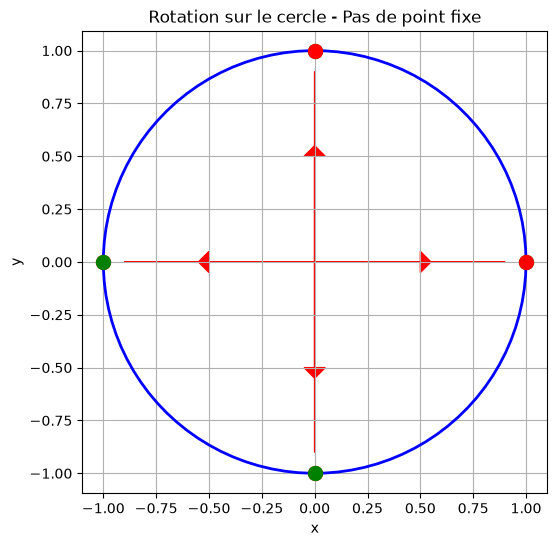

In [12]:
print("="*70)
print("CONTRE-EXEMPLE 3: Domaine non convexe")
print("="*70)
print("""
Sur le cercle S^1 (compact mais non convexe):

    f(theta) = theta + pi  (mod 2*pi)

C'est une rotation de 180 degres.

Point fixe? f(theta) = theta  =>  theta + pi = theta  =>  pi = 0 (mod 2*pi)

Contradiction! Pas de point fixe car on peut "tourner sans jamais revenir".
""")

# Illustration
theta = np.linspace(0, 2*np.pi, 100)
plt.figure(figsize=(6, 6))
plt.plot(np.cos(theta), np.sin(theta), 'b-', linewidth=2)

# Quelques points et leurs images
for t in [0, np.pi/2, np.pi, 3*np.pi/2]:
    x, y = np.cos(t), np.sin(t)
    x2, y2 = np.cos(t + np.pi), np.sin(t + np.pi)
    plt.arrow(x*0.9, y*0.9, (x2-x)*0.7, (y2-y)*0.7, 
              head_width=0.1, head_length=0.05, fc='red', ec='red')
    plt.scatter([x], [y], color='green', s=100, zorder=5)
    plt.scatter([x2], [y2], color='red', s=100, zorder=5)

plt.axis('equal')
plt.title('Rotation sur le cercle - Pas de point fixe')
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True)
plt.show()

### Interpretation : Domaine non convexe

La visualisation montre une rotation de 180 degrés sur le cercle unite S^1. Chaque point (vert) est mappe a son oppose (rouge) par la fonction.

**Observation geometrique** : Il n'y a aucun point fixe car une rotation non-triviale deplace tous les points du cercle.

| Propriete | Cercle S^1 | Simplexe [0,1] |
|-----------|------------|----------------|
| Compact | Oui (borne et ferme) | Oui |
| Convexe | **Non** (segment reliant deux points sort du cercle) | Oui |
| Brouwer applicable | **Non** | Oui |

**Pourquoi la convexite est necessaire** : Sur un domaine non convexe, on peut "tourner" les points sans jamais avoir de point fixe. La rotation est l'exemple canonique sur le cercle.

> **Lien avec les jeux** : L'espace des stratégies mixtes est un produit de simplexes, donc convexe. C'est pourquoi le theoreme de Brouwer s'y applique et garantit l'existence d'equilibres de Nash.

***

## Exercice 1 : Calcul d'equilibre de Nash

**Objectifs** :
1. Modeliser un jeu bi-matrice 2x2
2. Implementer la recherche d'equilibres de Nash purs
3. Verifier l'existence avec le theoreme de Nash

**Contexte** : Deux entreprises choisissent simultanement leur prix (Haut ou Bas). Les gains dependent de la combinaison des choix.

**Questions** :
1. Combien d'equilibres de Nash purs existe-t-il ?
2. Existe-t-il un equilibre en stratégies mixtes ?
3. L'equilibre est-il Pareto-optimal ?


In [13]:
# Exercice 1 : Calcul d'equilibre de Nash
import numpy as np

# ---- Donnees du probleme ----
# Jeu de competition en prix : deux entreprises choisissent Prix Haut (H) ou Bas (B)
# Matrice des gains (ligne = choix J1, colonne = choix J2)
#
#              J2: Haut   J2: Bas
# J1: Haut      (5,5)     (1,6)
# J1: Bas       (6,1)     (2,2)
#
# Interpretation : si les deux fixent un prix haut, profit 5 chacun.
# Si l'un baisse seul, il capte le marche (gain 6) au detriment de l'autre (gain 1).
# Si les deux baissent, le profit est faible pour tous (gain 2).

A = np.array([[5, 1],   # Gains joueur 1
              [6, 2]])
B = np.array([[5, 6],   # Gains joueur 2
              [1, 2]])

actions = ["Haut", "Bas"]
n_actions = len(actions)

print("Matrice de gains du jeu de competition en prix :")
print(f"  Actions : {actions}")
print(f"  Gains J1 (A) :\n{A}")
print(f"  Gains J2 (B) :\n{B}")
print()

# ---- Partie 1 : Equilibres de Nash purs ----

def find_pure_nash(A: np.ndarray, B: np.ndarray) -> list:
    """
    Trouve tous les equilibres de Nash en strategies pures.

    Args:
        A: Matrice de gains du joueur 1 (n x m)
        B: Matrice de gains du joueur 2 (n x m)

    Returns:
        Liste de tuples (i, j) representant les equilibres de Nash purs
    """
    n, m = A.shape
    equilibria = []

    # TODO: Pour chaque profil (i, j), verifier s'il est un equilibre de Nash
    # Indice: (i, j) est un Nash pur si et seulement si :
    #   - A[i, j] >= A[k, j] pour tout k (J1 ne peut pas ameliorer en changeant de ligne)
    #   - B[i, j] >= B[i, l] pour tout l (J2 ne peut pas ameliorer en changeant de colonne)

    return equilibria

nash_purs = find_pure_nash(A, B)
print(f"Nombre d'equilibres de Nash purs : {len(nash_purs)}")
for (i, j) in nash_purs:
    print(f"  ({actions[i]}, {actions[j]}) -> gains = ({A[i,j]}, {B[i,j]})")
print()

# ---- Partie 2 : Equilibre en strategies mixtes ----

def find_mixed_nash_2x2(A: np.ndarray, B: np.ndarray) -> tuple:
    """
    Calcule l'equilibre de Nash en strategies mixtes pour un jeu 2x2.

    Args:
        A: Matrice de gains du joueur 1 (2x2)
        B: Matrice de gains du joueur 2 (2x2)

    Returns:
        (p, q) ou p = P(J1 joue Haut) et q = P(J2 joue Haut)
        Retourne (None, None) si pas d'equilibre mixte
    """
    # TODO: Resoudre le systeme d'indifference
    # Indice : J2 est indifferent quand J1 joue p*Haut + (1-p)*Bas tel que
    #   les gains esperes de J2 sont egaux pour ses deux actions.
    # Idem pour J1 avec q.
    # Attention: verifier que le denominateur n'est pas nul
    # et que 0 <= p <= 1 et 0 <= q <= 1

    p = None  # TODO: calculer p*
    q = None  # TODO: calculer q*

    return p, q

p_star, q_star = find_mixed_nash_2x2(A, B)
if p_star is not None and q_star is not None:
    print(f"Equilibre en strategies mixtes :")
    print(f"  J1 : p(Haut) = {p_star:.4f}, p(Bas) = {1-p_star:.4f}")
    print(f"  J2 : q(Haut) = {q_star:.4f}, q(Bas) = {1-q_star:.4f}")
    sigma1 = np.array([p_star, 1 - p_star])
    sigma2 = np.array([q_star, 1 - q_star])
    gain1 = sigma1 @ A @ sigma2
    gain2 = sigma1 @ B @ sigma2
    print(f"  Gain espere J1 : {gain1:.4f}")
    print(f"  Gain espere J2 : {gain2:.4f}")
else:
    print("Pas d'equilibre en strategies mixtes (ou division par zero).")
print()

# ---- Partie 3 : Analyse Pareto ----

# TODO: Determiner si l'equilibre de Nash est Pareto-optimal
# Un profil (i,j) est Pareto-domine s'il existe (i',j') tel que :
#   A[i',j'] >= A[i,j] ET B[i',j'] >= B[i,j] avec au moins une inegalite stricte
# Comparez les gains a l'equilibre avec le profil (Haut, Haut)

print("Analyse Pareto :")
# TODO: implementer la verification de Pareto-optimalite

Matrice de gains du jeu de competition en prix :
  Actions : ['Haut', 'Bas']
  Gains J1 (A) :
[[5 1]
 [6 2]]
  Gains J2 (B) :
[[5 6]
 [1 2]]

Nombre d'equilibres de Nash purs : 0

Pas d'equilibre en strategies mixtes (ou division par zero).

Analyse Pareto :


### Interpretation : Jeu de competition en prix

Le jeu presente est un dilemme du prisonnier modifie ou les deux entreprises ont intérêt a baisser leurs prix, mais le profil collectivement optimal serait de maintenir des prix hauts.

**Structure des gains** :

| Profil | Gains (J1, J2) | Interpretation |
|--------|----------------|----------------|
| (Haut, Haut) | (5, 5) | Optimum social (Pareto) |
| (Haut, Bas) | (1, 6) | J2 profite de sa position basse |
| (Bas, Haut) | (6, 1) | J1 profite de sa position basse |
| (Bas, Bas) | (2, 2) | Equilibre de Nash (guerre des prix) |

**Questions guidees pour l'implementation** :
1. **Nash purs** : Verifiez si chaque joueur a intérêt a devier unilateralement de chaque profil
2. **Nash mixte** : Resolvez le système d'indifference (les gains esperes doivent etre egaux pour les deux actions)
3. **Pareto-optimalite** : Comparez l'equilibre de Nash avec le profil (Haut, Haut)

> **Indice pour la partie 2** : Pour un jeu 2x2, les probabilites p et q de l'equilibre mixte satisfont un système lineaire. Si J2 est indifferent, alors le gain esperé de J2 quand il joue Haut doit egaler le gain esperé quand il joue Bas.

***

## Exercice 2 : Dynamique de meilleure reponse

**Objectifs** :
1. Implementer une dynamique de meilleure reponse iterative
2. Observer la convergence vers un equilibre de Nash
3. Analyser les conditions de convergence

**Contexte** : Les joueurs ajustent iterativement leur stratégie en choisissant la meilleure reponse a la stratégie adverse actuelle.


In [14]:
# Exercice 2 : Dynamique de meilleure reponse
import numpy as np
import matplotlib.pyplot as plt

# ---- Donnees du probleme ----
# On utilise un jeu de coordination (differente structure que l'exercice 1)
# pour observer la convergence de la dynamique de meilleure reponse.
#
#              J2: A      J2: B
# J1: A       (4,4)      (1,3)
# J1: B       (3,1)      (2,2)
#
# Ce jeu a deux equilibres de Nash purs : (A,A) et (B,B).
# La dynamique convergera-t-elle ? Vers lequel ?

A = np.array([[4, 1],   # Gains joueur 1
              [3, 2]])
B = np.array([[4, 3],   # Gains joueur 2
              [1, 2]])

actions = ["A", "B"]

# ---- Partie 1 : Meilleure reponse en strategies pures ----

def best_response_pure(U: np.ndarray, opponent_action: int) -> int:
    """
    Calcule la meilleure reponse en strategie pure.

    Args:
        U: Matrice de gains du joueur (n x m)
        opponent_action: Index de l'action jouee par l'adversaire

    Returns:
        Index de la meilleure reponse
    """
    # TODO: Retourner l'action qui maximise le gain contre opponent_action
    pass

# ---- Partie 2 : Meilleure reponse en strategies mixtes ----

def best_response_mixed(U: np.ndarray, opponent_mix: np.ndarray, epsilon: float = 0.0) -> np.ndarray:
    """
    Calcule la meilleure reponse en strategie mixte (lissee par softmax).

    Args:
        U: Matrice de gains du joueur (n x m)
        opponent_mix: Strategie mixte de l'adversaire (vecteur de probabilites)
        epsilon: Temperature du softmax (0 = BR pure, >0 = lissee)

    Returns:
        Strategie mixte de meilleure reponse (vecteur de probabilites)
    """
    # TODO: Calculer le gain espere pour chaque action pure (produit matrice-vecteur)
    # TODO: Si epsilon == 0, retourner la strategie pure optimale (vecteur one-hot)
    # TODO: Si epsilon > 0, utiliser un softmax pour lisser la reponse
    #   Indice : softmax(x_i) = exp(x_i / epsilon) / sum(exp(x_j / epsilon))
    #   Astuce stabilite : soustraire max(x) avant l'exponentielle
    pass

# ---- Partie 3 : Boucle de dynamique ----

max_iter = 50
sigma1 = np.array([0.3, 0.7])  # Strategie initiale J1 (favorise B)
sigma2 = np.array([0.6, 0.4])  # Strategie initiale J2 (favorise A)

history_s1 = [sigma1.copy()]
history_s2 = [sigma2.copy()]

# TODO: Implementer la boucle de dynamique de meilleure reponse
# A chaque iteration :
#   1. J1 calcule sa meilleure reponse a sigma2 (utiliser best_response_mixed avec epsilon > 0)
#   2. J2 calcule sa meilleure reponse a sigma1
#   3. Mettre a jour sigma1 et sigma2
#   4. Enregistrer dans history_s1 et history_s2
#   5. Verifier la convergence (norme de la difference < seuil)

# ---- Partie 4 : Visualisation ----

# TODO: Apres avoir implemente la boucle, tracer :
#   - Evolution de P(A) pour les deux joueurs en fonction des iterations
#   - Trajectoire dans l'espace des strategies (P(A)_J1 vs P(A)_J2)

# ---- Partie 5 : Questions d'analyse ----

# TODO: Repondre aux questions suivantes (en commentaire ou dans une cellule markdown)
# Q1: Que se passe-t-il si epsilon = 0 (meilleure reponse pure) ? La dynamique converge-t-elle ?
# Q2: Quel est l'effet du parametre epsilon sur la vitesse de convergence ?
# Q3: L'equilibre atteint depend-il du point de depart (sigma1_init, sigma2_init) ?
# Q4: Essayez avec le jeu Matching Pennies (U1 = [[1,-1],[-1,1]], U2 = -U1).
#     La dynamique converge-t-elle ? Pourquoi ?
print("Exercice a completer : Dynamique de meilleure reponse")


Exercice a completer : Dynamique de meilleure reponse


### Exercice 3 : Verificateur d'hypotheses du theoreme de Brouwer

Le theoreme de Brouwer garantit l'existence d'un point fixe $f(x^*) = x^*$ si trois hypotheses sont satisfaites : domaine **compact**, **convexe**, et fonction **continue**.

**Objectif** : Implementer `verify_brouwer_hypotheses` qui verifie ces trois conditions sur des données discretisees et predit si un point fixe doit exister.

- **Indice :** Pour "compact", verifier que les points sont dans un rayon fini. Pour "convexe", verifier que le milieu de tout couple de points est dans l'enveloppe. Pour "continue", verifier que |f(x_{i+1}) - f(x_i)| ne fait pas de saut.
- **Étape 1 :** Implementer le test de compacite (norme maximale des points)
- **Étape 2 :** Implementer le test de convexite (enveloppe convexe via coefficient de Gini ou ratio)
- **Étape 3 :** Implementer le test de continuite (saut maximal entre points consecutifs < seuil)
- **Étape 4 :** Combiner les 3 tests et afficher le verdict

In [15]:
# Exercice 3 : Verificateur d'hypotheses du theoreme de Brouwer

def verify_brouwer_hypotheses(domain_points, function_values):
    """
    Verifie si les hypotheses du theoreme de Brouwer sont satisfaites
    pour un ensemble de points et leur image par une fonction.

    Retourne un dict avec les cles :
    - "compact": bool (ensemble ferme borne)
    - "convex": bool (ensemble convexe)
    - "continuous": bool (pas de saut > seuil entre points consecutifs)
    - "all_satisfied": bool (les 3 hypotheses)
    """
    # TODO etudiant : implementer la verification
    print("Exercice a completer : verify_brouwer_hypotheses")
    return {"compact": None, "convex": None, "continuous": None, "all_satisfied": None}  # TODO etudiant

# Test 1 : Segment [0, 1] avec f(x) = x^2 (hypotheses OK)
t = np.linspace(0, 1, 100)
domain1 = np.column_stack([t, 1 - t])  # segment sur le simplexe
vals1 = np.column_stack([t**2, 1 - t**2])
result1 = verify_brouwer_hypotheses(domain1, vals1)
print(f"Test 1 (segment, x^2) : {result1}")

# Test 2 : Cercle unite (non convexe en termes de domaine discret)
theta = np.linspace(0, 2*np.pi, 50, endpoint=False)
domain2 = np.column_stack([np.cos(theta), np.sin(theta)])
vals2 = np.column_stack([-np.cos(theta), -np.sin(theta)])  # rotation 180
result2 = verify_brouwer_hypotheses(domain2, vals2)
print(f"Test 2 (cercle, rotation) : {result2}")

# Test 3 : Fonction discontinue sur [0, 1]
t3 = np.linspace(0, 1, 100)
domain3 = np.column_stack([t3, 1 - t3])
vals3 = domain3.copy()
# Creer un saut
vals3[50:] = vals3[50:] + 1.0
result3 = verify_brouwer_hypotheses(domain3, vals3)
print(f"Test 3 (discontinue) : {result3}")

Exercice a completer : verify_brouwer_hypotheses
Test 1 (segment, x^2) : {'compact': None, 'convex': None, 'continuous': None, 'all_satisfied': None}
Exercice a completer : verify_brouwer_hypotheses
Test 2 (cercle, rotation) : {'compact': None, 'convex': None, 'continuous': None, 'all_satisfied': None}
Exercice a completer : verify_brouwer_hypotheses
Test 3 (discontinue) : {'compact': None, 'convex': None, 'continuous': None, 'all_satisfied': None}


### Interpretation : Dynamique de meilleure reponse

Le code fournit un squelette pour implementer et observer la convergence des stratégies vers un equilibre de Nash.

**Structure de l'exercice** :

| Étape | Objectif | Concept clé |
|-------|----------|-------------|
| 1 | Meilleure reponse pure | Stratégie optimale contre action fixe |
| 2 | Meilleure reponse mixte lissee | Softmax pour eviter les oscillations |
| 3 | Boucle de dynamique | Itération jusqu'a convergence |
| 4 | Visualisation | Trajectoire dans l'espace des stratégies |
| 5 | Analyse parametrique | Rôle d'epsilon, point de depart, structure du jeu |

**Points cles de l'implementation** :
- La fonction `best_response_mixed` doit calculer les gains esperes pour chaque action pure via un produit matrice-vecteur
- Le paramètre `epsilon` contrôle la "temperature" du softmax : epsilon = 0 correspond a la meilleure reponse pure, epsilon > 0 lisse la transition
- La convergence depend de la structure du jeu (coordination vs antagoniste)

> **Question de reflexion** : Pourquoi le jeu de coordination converge-t-il vers un equilibre, alors que Matching Pennies (jeu a somme nulle) peut osciller indefiniment ?

## Resume et perspectives

Ce notebook a illustre numeriquement le fondement mathematique du theoreme d'existence de Nash : le theoreme du point fixe de Brouwer. Nous avons implemente des algorithmes de recherche de points fixes en 1D (méthode de Babylone) et sur le simplexe 2D, puis observe la convergence des dynamiques de meilleure reponse perturbee vers l'equilibre de Matching Pennies (0.5, 0.5). Les contre-exemples ont montre pourquoi chaque hypothese de Brouwer est necessaire : un domaine non compact permet la fuite a l'infini, une fonction discontinue peut sauter par-dessus la diagonale, et un domaine non convexe autorise les rotations sans point fixe.

La lecture guidee du depot math-xmum/Brouwer a revele la chaîne de preuves formelle en Lean 4 : Lemme de Scarf (combinatoire des colorages) puis Lemme de Sperner puis Brouwer sur le simplexe puis extension au produit de simplexes puis existence de Nash. Cette architecture modulaire, ou un résultat combinatoire profond engendre par deductions successives le theoreme de Nash, illustre la puissance des mathematiques formalisees.

Le notebook companion [GameTheory-04b-Lean-NashExistence-Lean](GameTheory-04b-Lean-NashExistence-Lean.ipynb) propose la formalisation Lean 4 correspondante, tandis que le notebook suivant dans la serie principale, [GameTheory-05-ZeroSum-Minimax-Python](GameTheory-05-ZeroSum-Minimax-Python.ipynb), specialise l'analyse aux jeux a somme nulle ou le theoreme minimax de Von Neumann fournit des garanties encore plus fortes.


### References academiques

- Brouwer, L.E.J. (1911). Uber Abbildung von Mannigfaltigkeiten. Mathematische Annalen 71(1):97-115.
- Kakutani, S. (1941). A Generalization of Brouwer's Fixed Point Theorem. Duke Mathematical Journal 8(3):457-459.
- Nash, J.F. (1950). Equilibrium Points in N-Person Games. Proceedings of the National Academy of Sciences 36(1):48-49.
- Nash, J.F. (1951). Non-Cooperative Games. Annals of Mathematics 54(2):286-295.



> **Lien avec la formalisation Lean** : Les concepts de ce notebook — simplexe standard, produit de simplexes, théorème de Brouwer (axiomatisé), structure `FiniteGame`, profils de stratégies mixtes et équilibre de Nash — sont construits interactivement dans le notebook compagnon [GT-4b-Lean-NashExistence](GameTheory-04b-Lean-NashExistence-Lean.ipynb) (kernel Lean 4), sans import Mathlib. La chaîne de preuves complète (Scarf → Sperner → Brouwer → Nash) est détaillée dans le dépôt externe `math-xmum/Brouwer` (Scarf.lean → Brouwer.lean → Brouwer_product.lean → Nash.lean).
> **Prolongement computationnel** : [GameTheory-04e — Oracles réflexifs](GameTheory-04e-Reflective-Oracles-Python.ipynb) — auto-référence, décision causale (CDT/EDT) et restriction finie vérifiée (#14450).

## 6. Resume

### Points cles

| Concept | Description |
|---------|-------------|
| **Brouwer** | Toute fonction continue $f: K \to K$ sur compact convexe a un point fixe |
| **Application Nash** | Un equilibre de Nash est un point fixe de la correspondance de meilleure reponse |
| **Condition compact** | Sans cette condition, la fonction peut "fuir a l'infini" |
| **Condition continue** | Sans cette condition, la fonction peut "sauter" par-dessus la diagonale |

### Ressources

- [math-xmum/Brouwer](https://github.com/math-xmum/Brouwer) - Formalisation complete en Lean 4
- [harfe/fixed-point-theorems-lean4](https://github.com/harfe/fixed-point-theorems-lean4) - Brouwer + Kakutani
- Nash, J. (1950). "Equilibrium Points in N-Person Games"

### Voir aussi

- Companion Lean : [GameTheory-04b-Lean-NashExistence-Lean](GameTheory-04b-Lean-NashExistence-Lean.ipynb) pour les formalisations

***

**Navigation** : [← GameTheory-04b-Lean-NashExistence-Lean](GameTheory-04b-Lean-NashExistence-Lean.ipynb) | [Index](GameTheory-01-Setup-Python.ipynb) | [GameTheory-04d-Marchandage-Asymetrique-Python →](GameTheory-04d-Marchandage-Asymetrique-Python.ipynb)